# COS40007 – Portfolio Assessment 3c: LSTM for Classification
**Dataset:** Seoul Bike Sharing Demand · **Target:** `demand_class` (Low / Medium / High), same as Portfolio 2

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

I0000 00:00:1793330412.119440     314 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793330412.171113     314 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793330413.760897     314 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


# Part A: Traditional Machine Learning Models
## A.1 Load and analyse the dataset

In [2]:
df = pd.read_csv("SeoulBikeData.csv", encoding="latin-1")
df.columns = ["date", "rented_bike_count", "hour", "temperature", "humidity", "wind_speed", "visibility",
              "dew_point_temperature", "solar_radiation", "rainfall", "snowfall", "seasons", "holiday",
              "functioning_day"]
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y")

# Same cleaning as Portfolio 1: remove closed hours and humidity = 0 sensor errors
df = df[(df["functioning_day"] == "Yes") & (df["humidity"] != 0)].drop(columns="functioning_day")
df = df.sort_values(["date", "hour"]).reset_index(drop=True)

# Same target as Portfolio 1/2: 3 balanced classes -> classification problem
class_names = ["Low", "Medium", "High"]
df["demand_class"] = pd.qcut(df["rented_bike_count"], q=3, labels=[0, 1, 2]).astype(int)

print("Shape:", df.shape)
df["demand_class"].value_counts().sort_index().rename(index=dict(enumerate(class_names)))

Shape: (8448, 14)


demand_class
Low       2816
Medium    2816
High      2816
Name: count, dtype: int64

In [3]:
# Engineered features from Portfolio 2
df["temp_x_hour"] = df["temperature"] * df["hour"]
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["is_weekend"] = (df["date"].dt.dayofweek >= 5).astype(int)
df["rush_workday"] = (df["hour"].isin([7, 8, 9, 17, 18, 19])
                      & (df["is_weekend"] == 0)
                      & (df["holiday"] == "No Holiday")).astype(int)
df["is_raining"] = (df["rainfall"] > 0).astype(int)
df["daily_rainfall"] = df.groupby("date")["rainfall"].transform("sum")

# Encode categorical features
df["holiday"] = (df["holiday"] == "Holiday").astype(int)
df = pd.concat([df, pd.get_dummies(df["seasons"], prefix="season", dtype=int)], axis=1)

feature_cols = ["hour", "temperature", "humidity", "wind_speed", "visibility", "dew_point_temperature",
                "solar_radiation", "rainfall", "snowfall", "holiday",
                "season_Autumn", "season_Spring", "season_Summer", "season_Winter",
                "temp_x_hour", "hour_sin", "hour_cos", "is_weekend", "rush_workday", "is_raining", "daily_rainfall"]
print("Number of features:", len(feature_cols))

Number of features: 21


## A.2 Preprocess the data

In [4]:
X = df[feature_cols]
y = df["demand_class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

# Fit the scaler on the training set only, then apply it to both sets
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train:", X_train_s.shape)
print("Test :", X_test_s.shape)

Train: (5913, 21)
Test : (2535, 21)


## A.3 Train the models

In [5]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
    "SVM (Portfolio 2, tuned)": SVC(kernel="rbf", C=100, gamma="scale"),
}

# Shuffle the folds because the data is sorted by time
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ml_results = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    cv_scores = cross_val_score(make_pipeline(StandardScaler(), model), X, y, cv=cv)
    ml_results[name] = {
        "Accuracy (%)": accuracy_score(y_test, pred) * 100,
        "F1 weighted (%)": f1_score(y_test, pred, average="weighted") * 100,
        "5-fold CV (%)": cv_scores.mean() * 100,
    }
    print(f"{name} done")

Random Forest done


MLP done


SVM (Portfolio 2, tuned) done


## A.4 Evaluate and compare

In [6]:
ml_table = pd.DataFrame(ml_results).T.round(2)
ml_table

,Accuracy (%),F1 weighted (%),5-fold CV (%)
Random Forest,88.88,88.85,88.55
MLP,86.67,86.70,86.83
"SVM (Portfolio 2, tuned)",88.21,88.22,87.14


**Best model: Random Forest** (88.88% accuracy, 88.85% weighted F1, 88.55% CV). It averages 200 trees, which captures non-linear weather × time interactions without heavy tuning and reduces the overfitting of a single Decision Tree (83.39% in Portfolio 2). The MLP is ~2 points lower: with ~6,000 samples and default settings it is harder to optimise than tree ensembles on tabular data.

## A.5 Visualise results

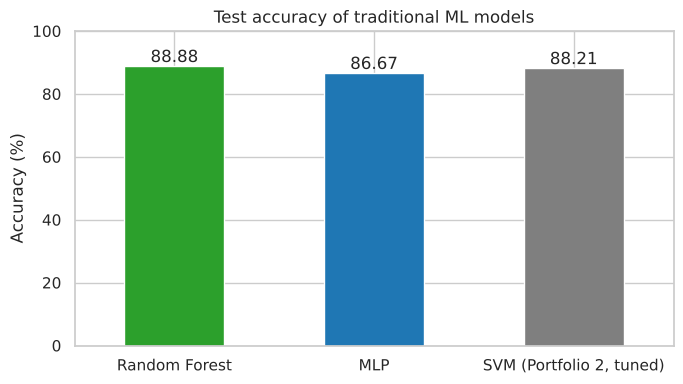

In [7]:
ax = ml_table["Accuracy (%)"].plot(kind="bar", figsize=(7, 4), rot=0, ylim=(0, 100), color=["tab:green", "tab:blue", "tab:grey"])
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.set_title("Test accuracy of traditional ML models")
ax.set_ylabel("Accuracy (%)")
plt.tight_layout()
plt.savefig("partA_accuracy.png", dpi=150)
plt.show()